# 05 · Daily bus demand forecasting

**Objective:** predict published daily boarding estimates for a fixed cohort of 41 Manhattan routes.
Issue a seven-day forecast each Monday at 00:00 America/New_York. Each prediction is a route/date
total, combining directions. The horizon is 1–7 days, including the issue date.

**Availability assumption:** exclude the seven complete dates immediately preceding issuance.
For a Monday issue, the latest available demand date is the Sunday eight days earlier.
This is an experimental assumption, not a verified MTA publication guarantee. The collection is a
single frozen, potentially revised extract; point-in-time data vintages are unavailable. Results are
retrospective, conditional on this assumption, rather than proof of deployable forecast performance.

This notebook loads the validated demand products directly. Run after notebook 02. Existing GTFS
alignment and EDA remain separate evidence; no schedule, target-derived service ratio or full-period
route profile is used as a predictor. The fixed route cohort is a retrospective study population.

In [1]:
from pathlib import Path
import sys, json, pickle, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'scripts/forecasting.py').exists())
sys.path.insert(0, str(ROOT/'scripts'))
from forecasting import (BASELINES, CONFIGS, FEATURES, load_inputs, make_examples,
                         backtest, metrics, training_rows, fit_model, predict, sha256, issue_cutoff)
OUT = ROOT/'data/processed/new_york/forecasting'
REPORT = ROOT/'reports/forecasting'
OUT.mkdir(parents=True, exist_ok=True)
(REPORT/'figures').mkdir(parents=True, exist_ok=True)
DELAY = 7
print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)
print('Forecast: seven daily route totals; assumed complete-date publication delay:', DELAY)

Python: 3.11.9 | pandas: 2.2.3 | scikit-learn: 1.8.0
Forecast: seven daily route totals; assumed complete-date publication delay: 7


## 1. Verify inputs and define the forecast population

Check the daily table and route crosswalk against the cleaning manifest. Preserve real zeros.
Unavailable targets remain unavailable. Quality flags follow the cleaning rules, including the
finer hourly screen available only in July–September 2026; performance across periods therefore
uses a changing quality-screen scope. Boardings are publisher estimates and transfers are included.

In [2]:
daily, routes = load_inputs(ROOT)
source_hashes = {name: sha256(ROOT/'data/processed/new_york'/name)
                 for name in ['daily_clean.csv','route_crosswalk.csv','cleaning_manifest.json']}
display(pd.DataFrame([{'routes':len(routes),'rows':len(daily),
    'first_date':daily.payment_date.min(),'last_date':daily.payment_date.max(),
    'review_or_unavailable_targets':daily.analysis_boardings.isna().sum(),
    'observed_zero_targets':daily.analysis_boardings.eq(0).sum()}]))
display(daily[['payment_date','bus_route','published_boardings','analysis_boardings']].head())

,routes,rows,first_date,last_date,review_or_unavailable_targets,observed_zero_targets
0,41,26158,2025-01-01,2026-09-30,287,172


,payment_date,bus_route,published_boardings,analysis_boardings
145,2025-01-01,M1,3007,3007.0
146,2025-01-01,M10,1580,1580.0
148,2025-01-01,M101,4602,4602.0
149,2025-01-01,M102,3263,3263.0
150,2025-01-01,M103,3341,3341.0


## 2. Construct examples with explicit information cutoffs

For each target date, look up the four latest same-weekday dates on or before the issue cutoff.
With the default seven-day delay these are exactly t−14, t−21, t−28 and t−35. The baseline uses
the latest available one or their mean. Require at least two valid seasonal observations for every
candidate, including baselines, so comparisons share the same eligible rows.

Predictors include route category, target calendar, horizon, trend and those seasonal observations.
Federal holidays describe a known calendar; they do not assert MTA holiday service. Missing lag
values remain missing and the tree handles them natively. No global imputation, target encoding,
scaling or randomly selected early-stopping subset is fitted. Training examples are weekly forecasts
with their own historical cutoffs, not features recalculated using their eventual target counts.

In [3]:
origins = pd.date_range('2025-03-03','2026-09-21',freq='W-MON')
examples = make_examples(daily, routes, origins, DELAY)
assert not examples.duplicated(['bus_route','payment_date']).any()
assert examples.max_history_date.le(examples.availability_cutoff).all()
display(examples[['bus_route','origin','availability_cutoff','payment_date','horizon',
    'max_history_date','weekly_lag_2','seasonal_mean4','actual']].head(8))
print('Historical examples:',len(examples),'| minimum-history exclusions:',int((~examples.history_eligible).sum()))

,bus_route,origin,availability_cutoff,payment_date,horizon,max_history_date,weekly_lag_2,seasonal_mean4,actual
0,M1,2025-03-03,2025-02-23,2025-03-03,1,2025-02-17,4652.0,6857.75,7898.0
1,M10,2025-03-03,2025-02-23,2025-03-03,1,2025-02-17,2230.0,2983.50,3275.0
2,M101,2025-03-03,2025-02-23,2025-03-03,1,2025-02-17,9304.0,13383.00,15164.0
3,M102,2025-03-03,2025-02-23,2025-03-03,1,2025-02-17,6172.0,8612.75,8979.0
4,M103,2025-03-03,2025-02-23,2025-03-03,1,2025-02-17,5384.0,6862.00,6619.0
5,M104,2025-03-03,2025-02-23,2025-03-03,1,2025-02-17,5286.0,5276.00,5297.0
6,M106,2025-03-03,2025-02-23,2025-03-03,1,2025-02-17,511.0,1439.25,1701.0
7,M11,2025-03-03,2025-02-23,2025-03-03,1,2025-02-17,5424.0,8128.75,8496.0


Historical examples: 23534 | minimum-history exclusions: 0


## 3. Fix development and test periods before fitting

Use eight weekly origins from 1 June–20 July 2026 for model selection; targets end 26 July.
Use eight later weekly origins held out from model selection, from 3 August–21 September for final evaluation; targets end
27 September. The intervening week is unused for selection or scoring. Earlier history supplies
expanding training windows. Each weekly fit only includes training targets available by its cutoff.

Choose the lowest validation MAE among two seasonal baselines and two fixed Poisson gradient-boosting
configurations (15 or 31 leaves; 120 iterations, fixed seed, early stopping disabled). Freeze this choice
before reading test errors. Earlier EDA examined these dates, so this is not a wholly unseen project dataset.
Weekly refits may use earlier test outcomes once the stated delay has
elapsed; this evaluates a rolling service, not one model frozen for two months. No test-period tuning.

In [4]:
validation_origins = pd.date_range('2026-06-01','2026-07-20',freq='W-MON')
test_origins = pd.date_range('2026-08-03','2026-09-21',freq='W-MON')
splits = pd.DataFrame([
    {'split':'validation','origins':len(validation_origins),'first_origin':validation_origins.min(),
     'last_target':validation_origins.max()+pd.Timedelta(days=6)},
    {'split':'test','origins':len(test_origins),'first_origin':test_origins.min(),
     'last_target':test_origins.max()+pd.Timedelta(days=6)}])
assert splits.iloc[0].last_target < splits.iloc[1].first_origin
display(splits)

,split,origins,first_origin,last_target
0,validation,8,2026-06-01,2026-07-26
1,test,8,2026-08-03,2026-09-27


In [5]:
validation, validation_audit = backtest(examples, validation_origins, BASELINES+list(CONFIGS), DELAY)
validation_scores = metrics(validation).sort_values(['mae','model']).reset_index(drop=True)
selected = validation_scores.iloc[0].model
best_ml = validation_scores.loc[validation_scores.model.isin(CONFIGS)].iloc[0].model
best_baseline = validation_scores.loc[validation_scores.model.isin(BASELINES)].iloc[0].model
display(validation_scores.round(3))
print('Frozen selection by validation MAE:',selected)
display(validation_audit.head())

Origin 2026-06-01: 18,122 training / 287 scored rows


Origin 2026-06-08: 18,409 training / 287 scored rows


Origin 2026-06-15: 18,696 training / 287 scored rows


Origin 2026-06-22: 18,983 training / 287 scored rows


Origin 2026-06-29: 19,270 training / 287 scored rows


Origin 2026-07-06: 19,557 training / 287 scored rows


Origin 2026-07-13: 19,844 training / 287 scored rows


Origin 2026-07-20: 20,131 training / 287 scored rows


,model,rows,routes,mae,rmse,wape,bias,actual_total
0,boosted_31,2296,41,441.658,687.925,0.082,-2.753,12339795.0
1,boosted_15,2296,41,451.271,706.217,0.084,26.533,12339795.0
2,seasonal_mean4,2296,41,505.143,841.360,0.094,156.788,12339795.0
3,seasonal_latest,2296,41,587.738,1003.178,0.109,37.346,12339795.0


Frozen selection by validation MAE: boosted_31


,origin,cutoff,train_rows,last_training_target,test_rows,first_test_date,last_test_date
0,2026-06-01,2026-05-24,18122,2026-05-24,287,2026-06-01,2026-06-07
1,2026-06-08,2026-05-31,18409,2026-05-31,287,2026-06-08,2026-06-14
2,2026-06-15,2026-06-07,18696,2026-06-07,287,2026-06-15,2026-06-21
3,2026-06-22,2026-06-14,18983,2026-06-14,287,2026-06-22,2026-06-28
4,2026-06-29,2026-06-21,19270,2026-06-21,287,2026-06-29,2026-07-05


## 4. Evaluate on later weeks using the frozen selection

Report both baselines and the validation-selected boosted configuration on identical test rows.
MAE and RMSE are in boardings per route/day; WAPE is total absolute error divided by total actual
boardings and gives higher-volume routes more weight. Positive bias means overprediction. Percentage
errors are not calculated per individual zero-demand row. These are prediction errors, not accuracy
or measures of bus occupancy. Report route-level and horizon-level results alongside pooled metrics.

With Monday issue dates, horizon 1 always falls on Monday and horizon 7 on Sunday.
Horizon diagnostics therefore also reflect weekday differences; they do not isolate the effect
of forecast distance. Route category and target calendar values are known at issuance.

In [6]:
test_names = list(dict.fromkeys(BASELINES+[best_ml]))
test, test_audit = backtest(examples, test_origins, test_names, DELAY)
test_scores = metrics(test).sort_values('mae').reset_index(drop=True)
assert test.groupby('model').size().nunique()==1
assert not test.duplicated(['model','bus_route','payment_date']).any()
assert test_audit.last_training_target.le(test_audit.cutoff).all()
display(test_scores.round(3))
display(test_audit)
selected_test = test.loc[test.model.eq(selected)].copy()
baseline_mae = float(test_scores.loc[test_scores.model.eq(best_baseline),'mae'].iloc[0])
selected_mae = float(test_scores.loc[test_scores.model.eq(selected),'mae'].iloc[0])
print(f'Selected approach MAE improvement versus validation-selected baseline: {100*(1-selected_mae/baseline_mae):.2f}%')

Origin 2026-08-03: 20,705 training / 287 scored rows


Origin 2026-08-10: 20,992 training / 246 scored rows


Origin 2026-08-17: 21,279 training / 287 scored rows


Origin 2026-08-24: 21,525 training / 287 scored rows


Origin 2026-08-31: 21,812 training / 287 scored rows


Origin 2026-09-07: 22,099 training / 287 scored rows


Origin 2026-09-14: 22,386 training / 287 scored rows


Origin 2026-09-21: 22,673 training / 287 scored rows


,model,rows,routes,mae,rmse,wape,bias,actual_total
0,boosted_31,2255,41,615.055,958.321,0.113,-90.219,12313679.0
1,seasonal_mean4,2255,41,630.779,989.207,0.116,-152.237,12313679.0
2,seasonal_latest,2255,41,698.224,1106.215,0.128,-105.221,12313679.0


,origin,cutoff,train_rows,last_training_target,test_rows,first_test_date,last_test_date
0,2026-08-03,2026-07-26,20705,2026-07-26,287,2026-08-03,2026-08-09
1,2026-08-10,2026-08-02,20992,2026-08-02,246,2026-08-10,2026-08-15
2,2026-08-17,2026-08-09,21279,2026-08-09,287,2026-08-17,2026-08-23
3,2026-08-24,2026-08-16,21525,2026-08-15,287,2026-08-24,2026-08-30
4,2026-08-31,2026-08-23,21812,2026-08-23,287,2026-08-31,2026-09-06
5,2026-09-07,2026-08-30,22099,2026-08-30,287,2026-09-07,2026-09-13
6,2026-09-14,2026-09-06,22386,2026-09-06,287,2026-09-14,2026-09-20
7,2026-09-21,2026-09-13,22673,2026-09-13,287,2026-09-21,2026-09-27


Selected approach MAE improvement versus validation-selected baseline: 2.49%


In [7]:
by_route = metrics(test, ('model','bus_route'))
by_horizon = metrics(test, ('model','horizon'))
expected = examples.loc[examples.origin.isin(test_origins)]
coverage = pd.DataFrame([{'expected_route_dates':len(expected),
    'unavailable_targets':expected.actual.isna().sum(),
    'insufficient_history_with_observed_target':(expected.actual.notna() & ~expected.history_eligible).sum(),
    'scored_route_dates':len(selected_test),'observed_zero_targets_scored':selected_test.actual.eq(0).sum()}])
display(coverage)
display(by_route.loc[by_route.model.eq(selected)].sort_values('mae',ascending=False).head(10).round(2))
display(by_horizon.round(3))
macro = by_route.groupby('model').agg(equal_route_mean_mae=('mae','mean'),
    equal_route_mean_wape=('wape','mean'),routes=('bus_route','nunique'))
display(macro.round(3))

,expected_route_dates,unavailable_targets,insufficient_history_with_observed_target,scored_route_dates,observed_zero_targets_scored
0,2296,41,0,2255,13


,model,bus_route,rows,routes,mae,rmse,wape,bias,actual_total
14,boosted_31,M15+,55,1,1953.62,2421.51,0.10,355.16,1101766.0
13,boosted_31,M15,55,1,1421.56,1883.18,0.11,-4.66,685436.0
37,boosted_31,M86+,55,1,1145.70,1627.93,0.10,-179.68,617484.0
25,boosted_31,M4,55,1,1119.24,1411.66,0.12,-59.73,520386.0
2,boosted_31,M101,55,1,1051.65,1469.43,0.10,-262.36,592668.0
12,boosted_31,M14D+,55,1,988.84,1312.91,0.10,-238.82,568223.0
31,boosted_31,M60+,55,1,883.81,1137.07,0.11,-397.90,435444.0
20,boosted_31,M3,55,1,870.71,1128.09,0.11,-133.25,426265.0
39,boosted_31,M96,55,1,866.00,1246.99,0.11,-384.55,429216.0
7,boosted_31,M11,55,1,863.75,1111.01,0.11,-250.15,419210.0


,model,horizon,rows,routes,mae,rmse,wape,bias,actual_total
0,boosted_31,1,328,41,614.739,939.546,0.113,51.096,1789519.0
1,boosted_31,2,328,41,601.526,967.041,0.098,-159.007,2013168.0
2,boosted_31,3,328,41,582.830,881.985,0.092,-195.293,2066713.0
3,boosted_31,4,328,41,749.604,1117.070,0.119,-201.208,2067097.0
4,boosted_31,5,328,41,554.695,874.616,0.092,-120.467,1983362.0
5,boosted_31,6,328,41,591.973,945.381,0.140,-6.375,1385737.0
6,boosted_31,7,287,41,609.301,963.028,0.173,12.567,1008083.0
7,seasonal_latest,1,328,41,833.415,1356.795,0.153,-71.000,1789519.0
8,seasonal_latest,2,328,41,728.052,1127.576,0.119,-189.759,2013168.0
9,seasonal_latest,3,328,41,687.119,1069.874,0.109,-151.668,2066713.0


,equal_route_mean_mae,equal_route_mean_wape,routes
model,,,
boosted_31,615.055,0.135,41
seasonal_latest,698.224,0.152,41
seasonal_mean4,630.779,0.138,41


## 5. Inspect performance over time and across routes

Network totals include only the scored route/date population. The scatter compares individual daily
predictions with observations. Weekly error shows whether average performance conceals a weak week.
Plots describe the historical evaluation window; no uncertainty interval has been calibrated.

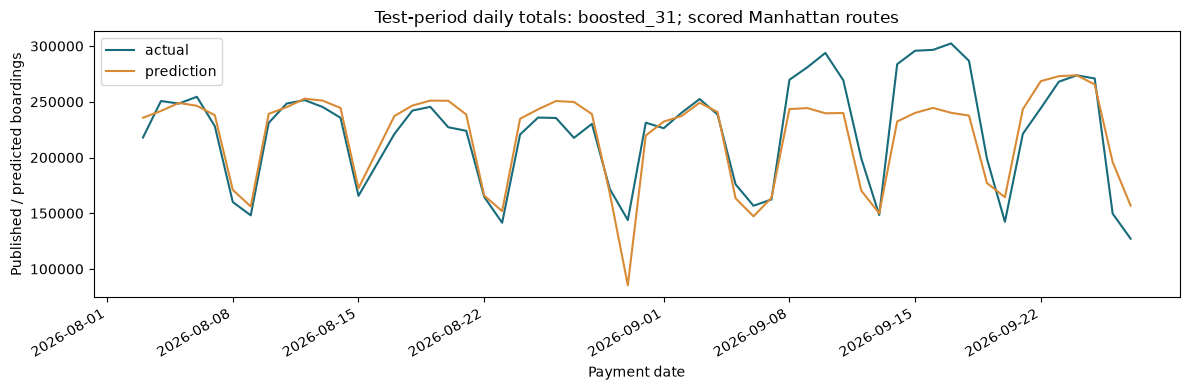

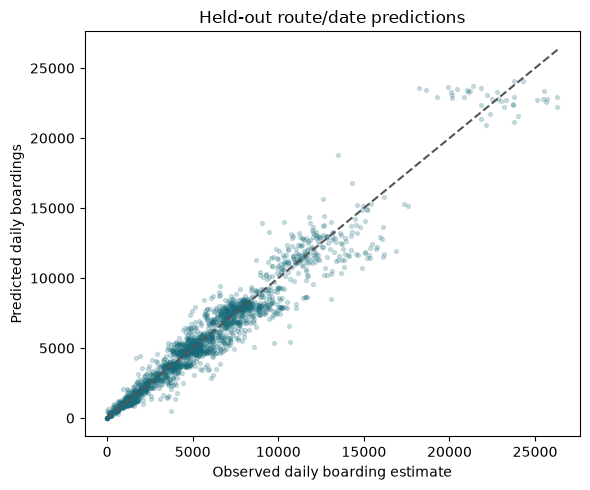

In [8]:
def save_figure(name):
    plt.tight_layout()
    plt.savefig(REPORT/'figures'/f'{name}.png',dpi=160,bbox_inches='tight')
    plt.show()

totals = selected_test.groupby('payment_date')[['actual','prediction']].sum()
fig,ax=plt.subplots(figsize=(12,4))
totals.plot(ax=ax,color=['#176b7a','#d98a35'])
ax.set(title=f'Test-period daily totals: {selected}; scored Manhattan routes',xlabel='Payment date',ylabel='Published / predicted boardings')
save_figure('test_daily_totals')
fig,ax=plt.subplots(figsize=(6,5))
ax.scatter(selected_test.actual,selected_test.prediction,s=8,alpha=.2,color='#176b7a')
limit=max(selected_test.actual.max(),selected_test.prediction.max())
ax.plot([0,limit],[0,limit],color='#555555',ls='--')
ax.set(xlabel='Observed daily boarding estimate',ylabel='Predicted daily boardings',title='Held-out route/date predictions')
save_figure('test_observed_predicted')

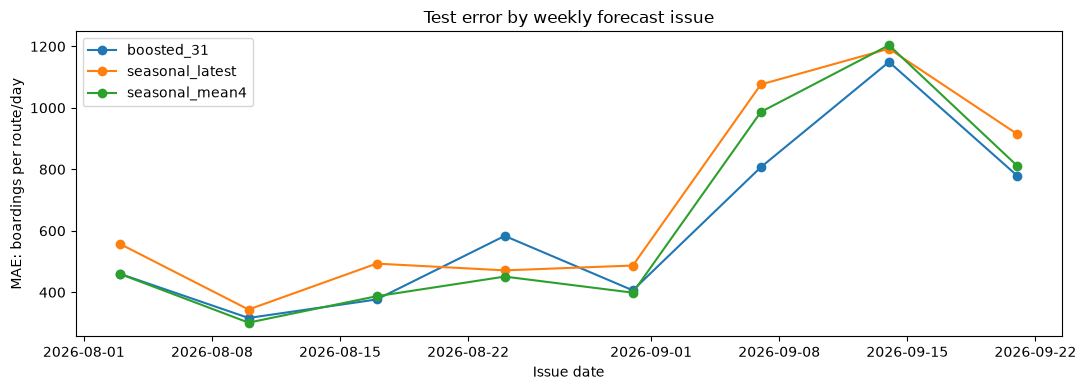

In [9]:
weekly_scores = metrics(test, ('model','origin'))
fig,ax=plt.subplots(figsize=(11,4))
for name,part in weekly_scores.groupby('model'):
    ax.plot(part.origin,part.mae,marker='o',label=name)
ax.set(title='Test error by weekly forecast issue',xlabel='Issue date',ylabel='MAE: boardings per route/day')
ax.legend()
save_figure('test_weekly_mae')

## 6. Check sensitivity to a longer publication delay

Repeat the frozen selection with a 28-complete-day delay, refitting the same chosen configuration
without tuning. Compare the same route/date rows available under both assumptions. This sensitivity
does not establish the true delay; historical publication and revision vintages are still needed.
The four seasonal lag columns store available same-weekday observations: their actual dates move
with the cutoff (the default column names describe the seven-day-delay experiment).

In [10]:
examples28 = make_examples(daily, routes, origins, delay_days=28)
sensitivity, sensitivity_audit = backtest(examples28, test_origins,
    list(dict.fromkeys([selected,best_baseline])), delay_days=28)
common = selected_test[['bus_route','payment_date']].merge(
    sensitivity.loc[sensitivity.model.eq(selected),['bus_route','payment_date']],
    on=['bus_route','payment_date'],validate='one_to_one')
sensitivity_scores=[]
for delay,table in [(7,test),(28,sensitivity)]:
    subset=table.merge(common,on=['bus_route','payment_date'],validate='many_to_one')
    score=metrics(subset.loc[subset.model.isin([selected,best_baseline])])
    score['assumed_delay_days']=delay
    sensitivity_scores.append(score)
sensitivity_scores=pd.concat(sensitivity_scores,ignore_index=True)
display(sensitivity_scores.round(3))

Origin 2026-08-03: 19,844 training / 287 scored rows


Origin 2026-08-10: 20,131 training / 246 scored rows


Origin 2026-08-17: 20,418 training / 287 scored rows


Origin 2026-08-24: 20,705 training / 287 scored rows


Origin 2026-08-31: 20,992 training / 287 scored rows


Origin 2026-09-07: 21,279 training / 287 scored rows


Origin 2026-09-14: 21,525 training / 287 scored rows


Origin 2026-09-21: 21,812 training / 287 scored rows


,model,rows,routes,mae,rmse,wape,bias,actual_total,assumed_delay_days
0,boosted_31,2255,41,615.055,958.321,0.113,-90.219,12313679.0,7
1,seasonal_mean4,2255,41,630.779,989.207,0.116,-152.237,12313679.0,7
2,boosted_31,2255,41,558.909,825.274,0.102,-281.431,12313679.0,28
3,seasonal_mean4,2255,41,611.794,949.286,0.112,-139.491,12313679.0,28


## 7. Refit and produce an illustrative seven-day forecast

The last complete source date is 30 September 2026. The next Monday is 5 October; under the assumed
delay, the final training target cutoff is 27 September. Refit the frozen selected approach and forecast
5–11 October. This is an illustrative outlook from a frozen historical collection, not a current or
previously issued forecast. The source was collected after that issue date. Observations for this
forecast window are unavailable in the collection, so no error is calculated for these predictions.

The exported model is a trusted local Python artifact if boosting is selected; baseline parameters
otherwise suffice. Metadata preserves feature order, route category mapping, versions and hashes.

In [11]:
forecast_origin = pd.Timestamp('2026-10-05')
outlook_rows=make_examples(daily,routes,[forecast_origin],DELAY)
assert outlook_rows.history_eligible.all()
final_train=training_rows(examples,forecast_origin,DELAY)
final_model=None
if selected in BASELINES:
    outlook_rows['prediction']=outlook_rows[selected]
else:
    final_model=fit_model(final_train,selected)
    outlook_rows['prediction']=predict(final_model,outlook_rows)
    with (OUT/'selected_model.pkl').open('wb') as handle:
        pickle.dump(final_model,handle)
outlook=outlook_rows[['bus_route','origin','availability_cutoff','payment_date','horizon','max_history_date','prediction']].copy()
outlook['model']=selected
assert outlook.prediction.ge(0).all()
display(outlook.head(10).round({'prediction':1}))
print('Illustrative forecast rows:',len(outlook),'| final training targets through:',final_train.payment_date.max().date())

,bus_route,origin,availability_cutoff,payment_date,horizon,max_history_date,prediction,model
0,M1,2026-10-05,2026-09-27,2026-10-05,1,2026-09-21,6576.5,boosted_31
1,M10,2026-10-05,2026-09-27,2026-10-05,1,2026-09-21,3227.1,boosted_31
2,M101,2026-10-05,2026-09-27,2026-10-05,1,2026-09-21,11455.3,boosted_31
3,M102,2026-10-05,2026-09-27,2026-10-05,1,2026-09-21,6176.1,boosted_31
4,M103,2026-10-05,2026-09-27,2026-10-05,1,2026-09-21,5294.2,boosted_31
5,M104,2026-10-05,2026-09-27,2026-10-05,1,2026-09-21,5105.6,boosted_31
6,M106,2026-10-05,2026-09-27,2026-10-05,1,2026-09-21,1133.5,boosted_31
7,M11,2026-10-05,2026-09-27,2026-10-05,1,2026-09-21,7907.4,boosted_31
8,M116,2026-10-05,2026-09-27,2026-10-05,1,2026-09-21,3953.8,boosted_31
9,M12,2026-10-05,2026-09-27,2026-10-05,1,2026-09-21,1033.3,boosted_31


Illustrative forecast rows: 287 | final training targets through: 2026-09-27


## 8. Save evaluation evidence and interpret the result

Model selection is determined by validation, even if test results later favor another candidate.
Benefits are conditional on a fixed route cohort, the stated delay, revision limitations and excluded
review dates. Changes in routes, fares or service may invalidate learned patterns. Daily forecasts do
not allocate passengers to directions, stops, hours or individual buses. Application integration,
uncertainty calibration and operational acceptance remain separate milestones.

In [12]:
products={'historical_examples':examples,'validation_predictions':validation,'test_predictions':test,
    'validation_scores':validation_scores,'test_scores':test_scores,'test_route_metrics':by_route,
    'test_horizon_metrics':by_horizon,'validation_origin_audit':validation_audit,'test_origin_audit':test_audit,
    'test_coverage':coverage,'delay_sensitivity_scores':sensitivity_scores,
    'delay_sensitivity_predictions':sensitivity,'delay_sensitivity_origin_audit':sensitivity_audit,
    'illustrative_forecast':outlook}
for name,table in products.items():
    table.to_csv(OUT/f'{name}.csv',index=False)
summary={'target':'published daily route boarding estimate','routes':len(routes),'horizon_days':7,
    'assumed_publication_delay_days':DELAY,'selected_model':selected,'best_validation_baseline':best_baseline,
    'validation_first_origin':str(validation_origins.min().date()),'validation_last_target':'2026-07-26',
    'test_first_origin':str(test_origins.min().date()),'test_last_target':'2026-09-27',
    'test_scores':test_scores.to_dict(orient='records'),
    'selected_test_mae_improvement_percent':100*(1-selected_mae/baseline_mae),
    'test_scored_route_dates':len(selected_test),'forecast_origin':str(forecast_origin.date()),
    'forecast_last_target':'2026-10-11','forecast_rows':len(outlook),
    'final_training_cutoff':str(issue_cutoff(forecast_origin,DELAY).date()),
    'release_delay_verified':False,'historical_data_vintages_available':False,
    'prediction_intervals_calibrated':False,'operational_deployment_validated':False}
metadata={'summary':summary,'features':FEATURES,'route_category_mapping':dict(enumerate(routes)),
    'model_configs':CONFIGS,'source_hashes':source_hashes,'python_version':platform.python_version(),
    'sklearn_version':sklearn.__version__,'numpy_version':np.__version__,'pandas_version':pd.__version__,
    'products':{name:{'rows':len(table),'sha256':sha256(OUT/f'{name}.csv')} for name,table in products.items()}}
if final_model is not None:
    metadata['model_sha256']=sha256(OUT/'selected_model.pkl')
(OUT/'forecast_manifest.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
(REPORT/'summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
assert source_hashes=={name:sha256(ROOT/'data/processed/new_york'/name) for name in source_hashes}
display(pd.DataFrame([{'selected_model':selected,'test_MAE':selected_mae,
    'test_WAPE':test_scores.loc[test_scores.model.eq(selected),'wape'].iloc[0],
    'improvement_vs_selected_baseline_percent':summary['selected_test_mae_improvement_percent']}]).round(3))
print('Saved',len(products),'forecast and evaluation tables; 3 figures; source fingerprints unchanged.')
print('Retrospective evaluation complete. Publication delay and data revisions remain operational validation requirements.')

,selected_model,test_MAE,test_WAPE,improvement_vs_selected_baseline_percent
0,boosted_31,615.055,0.113,2.493


Saved 14 forecast and evaluation tables; 3 figures; source fingerprints unchanged.
Retrospective evaluation complete. Publication delay and data revisions remain operational validation requirements.


## Result interpretation

Validation selected the 31-leaf boosted model. On 2,255 later route/date observations its MAE is
**615.06 boardings**, versus **630.78** for the seasonal mean baseline: a **2.49% reduction**.
Its WAPE is **11.26%**. This modest improvement is conditional on the assumed publication delay,
fixed cohort and frozen revised data. Weekly plots show higher September errors and underprediction
of some larger values. These patterns warrant investigation without asserting a cause.

The 28-day-delay sensitivity gives MAE **558.91** versus its baseline **611.79**; it does not identify
the true publication delay. The final 287-row outlook covers **5-11 October 2026**, with no observed
outcomes in this collection. Independent future evaluation and calibrated uncertainty are needed
before operational use. See [forecasting protocol and results](../../documentation/FORECASTING.md).

## Independent verification and stability

The independent audit in `scripts/audit_forecast.py` verifies the 57 original source fingerprints,
14 forecast products, all 23,534 historical feature rows and 94,136 lag lookups. Recalculation
confirms the recorded validation/test errors, equal scoring populations and training cutoffs.

The selected model improves MAE in **4 of 8 test weeks** and **25 of 41 routes**. August MAE is
**438.86**, versus baseline **401.79**; September MAE is **797.77**, versus baseline **868.25**.
The overall 2.49% gain therefore does not imply consistent improvement for every period or route.

Resampling whole issue weeks 10,000 times (seed 42) yields a central 95% stability range of
**-8.15% to +10.14%** for MAE improvement. This is exploratory: eight weekly clusters and possible
temporal dependence limit interpretation. It is neither formal significance evidence nor a
prediction interval. Reliable superiority over the seasonal baseline remains unestablished.

Run `python scripts/audit_forecast.py` from the repository root to reproduce the checks and save
the detailed local audit. Existing model predictions and evaluation outputs are unchanged.